# AI Model Challenge 1 – GTSRB (Version 4, Fehler behoben)
TensorFlow/Keras · Adam · Cross-Entropy · RGB 48×48 · max. 10 Epochen · from scratch (keine vortrainierten Modelle)

**Wichtigster Fix:** Die Augmentation läuft jetzt auf den Rohwerten 0–255 und erst danach kommt `Rescaling(1/255)`. In der Vorversion war die Reihenfolge falsch, deshalb lag die Test-Accuracy bei ca. 3,6 %.

**Weitere Verbesserungen:** Warmup + Cosine-LR · Sanity-Check der Augmentation vor dem Training · Test-Time-Augmentation (nur aktiv, wenn sie auf der Validierung hilft) · Split nach Tracks · Autocontrast · ResNet + SE · Label Smoothing · abgeschwächte Klassengewichte.

In [1]:
import os, time, json, math
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageOps
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
from types import SimpleNamespace

args = SimpleNamespace(
    data_dir="./gtsrb",   # <- Pfad anpassen (wird automatisch gesucht)
    img_size=48,          # 32 oder 48
    epochs=10,            # Maximum laut Aufgabe
    batch=64,
    lr=2e-3,
    warmup_frac=0.1,      # 10 % der Schritte Warmup
    label_smoothing=0.05, # weiterhin Cross-Entropy
    out="outputs_v3",
)
SEED, NUM_CLASSES, S = 42, 43, args.img_size
tf.random.set_seed(SEED); np.random.seed(SEED)
os.makedirs(args.out, exist_ok=True)

## 1. Datensatz finden

In [2]:
def find_dataset_root(start):
    for base in [start, "/content/gtsrb", "/kaggle/input", os.getcwd(), os.path.expanduser("~")]:
        if not os.path.isdir(base):
            continue
        if os.path.isdir(os.path.join(base, "Train")):
            return base
        for root, dirs, _ in os.walk(base):
            if "Train" in dirs:
                return root
            if root.count(os.sep) - base.count(os.sep) >= 4:
                dirs[:] = []
    return None

root = find_dataset_root(args.data_dir)
if root is None:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub
    root = find_dataset_root(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))
if root is None:
    raise FileNotFoundError("Kein 'Train'-Ordner gefunden. Setze args.data_dir manuell.")
args.data_dir = root
print("Datensatz:", root, os.listdir(root))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Datensatz: /kaggle/input/gtsrb-german-traffic-sign ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


## 2. Laden + Vorverarbeitung

In [3]:
def load_img(path):
    img = Image.open(path).convert("RGB")
    img = ImageOps.autocontrast(img, cutoff=1)          # Kontrast normalisieren (dunkle Bilder)
    return np.asarray(img.resize((S, S), Image.BILINEAR), dtype=np.uint8)

train_dir = os.path.join(root, "Train")
class_dirs = sorted([d for d in os.listdir(train_dir) if d.isdigit()], key=int)
assert len(class_dirs) == NUM_CLASSES, f"{len(class_dirs)} Klassen gefunden"

X, y, groups = [], [], []
for d in class_dirs:
    label = int(d)
    for f in sorted(os.listdir(os.path.join(train_dir, d))):
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".ppm")):
            X.append(load_img(os.path.join(train_dir, d, f)))
            y.append(label)
            parts = f.split("_")                         # Format: <Track>_<Frame>.png oder Klasse_Track_Frame.png
            groups.append(f"{label}_{parts[-2] if len(parts) >= 2 else f}")
X, y, groups = np.array(X), np.array(y), np.array(groups)
print("Train:", X.shape, "| Klassen:", len(np.unique(y)), "| Tracks:", len(np.unique(groups)))

Train: (39209, 48, 48, 3) | Klassen: 43 | Tracks: 1307


## 3. Exploration

Klassenungleichgewicht: min=210 max=2250 Verhältnis=10.7
Mittlere Helligkeit: 90.1  (0-255)


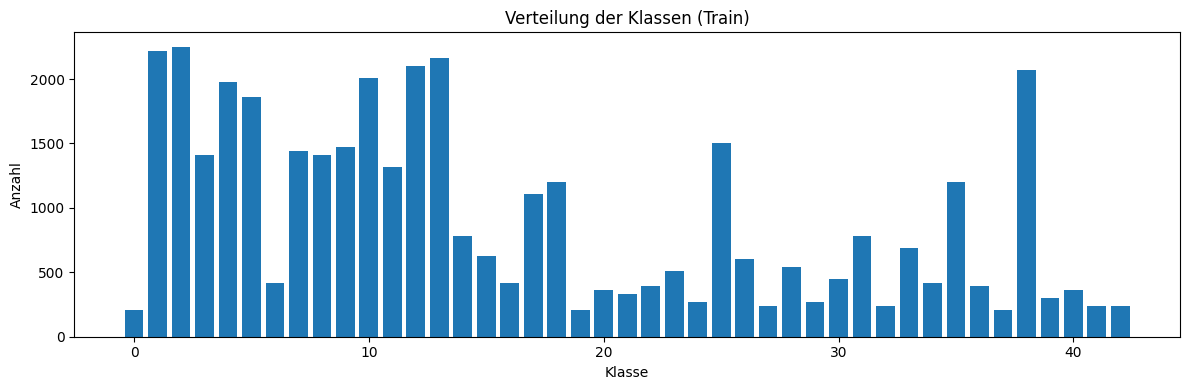

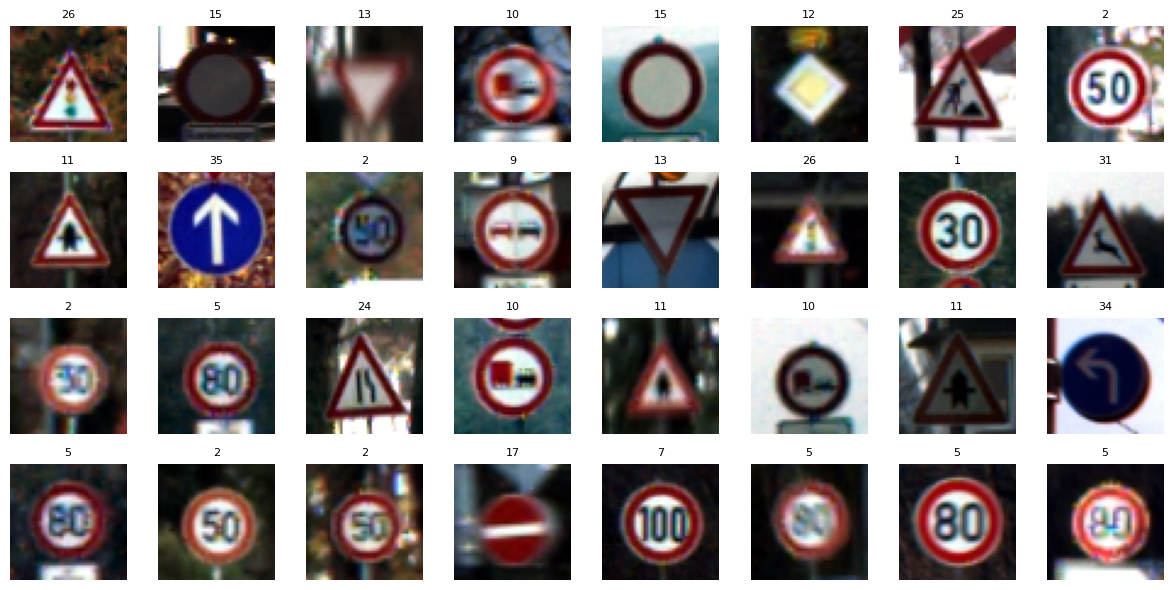

In [4]:
counts = np.bincount(y, minlength=NUM_CLASSES)
print(f"Klassenungleichgewicht: min={counts.min()} max={counts.max()} Verhältnis={counts.max()/counts.min():.1f}")
print(f"Mittlere Helligkeit: {X.mean():.1f}  (0-255)")
plt.figure(figsize=(12, 4)); plt.bar(range(NUM_CLASSES), counts)
plt.title("Verteilung der Klassen (Train)"); plt.xlabel("Klasse"); plt.ylabel("Anzahl")
plt.tight_layout(); plt.savefig(f"{args.out}/class_distribution.png", dpi=120); plt.show()

fig, ax = plt.subplots(4, 8, figsize=(12, 6))
for a, i in zip(ax.ravel(), np.random.choice(len(X), 32, replace=False)):
    a.imshow(X[i]); a.set_title(str(y[i]), fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(f"{args.out}/samples.png", dpi=120); plt.show()

## 4. Split nach Tracks (kein Leakage)

In [5]:
if len(np.unique(groups)) > NUM_CLASSES:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    tr_idx, val_idx = next(gss.split(X, y, groups))
    print("Gruppen-Split (nach Track) verwendet")
else:
    tr_idx, val_idx = train_test_split(np.arange(len(X)), test_size=0.15, stratify=y, random_state=SEED)
    print("Zufälliger stratifizierter Split verwendet")
X_tr, y_tr, X_val, y_val = X[tr_idx], y[tr_idx], X[val_idx], y[val_idx]
print("Train:", len(X_tr), "| Val:", len(X_val))

# Abgeschwächte Klassengewichte (Wurzel) -> weniger aggressiv als "balanced"
cw = np.sqrt(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr))
cw = cw / cw.mean()

def make_ds(Xa, ya, train):
    yo = tf.one_hot(ya, NUM_CLASSES)
    if train:
        sw = cw[ya].astype("float32")
        ds = tf.data.Dataset.from_tensor_slices((Xa, yo, sw)).shuffle(10000, seed=SEED)
    else:
        ds = tf.data.Dataset.from_tensor_slices((Xa, yo))
    return ds.batch(args.batch).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(X_tr, y_tr, True), make_ds(X_val, y_val, False)

Gruppen-Split (nach Track) verwendet
Train: 33299 | Val: 5910


## 5. Architektur: kleines ResNet mit SE

In [6]:
augment = keras.Sequential([
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.12),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augmentation")      # kein Flip: würde Schilder verfälschen

def se_block(x, ratio=8):
    f = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(f // ratio, activation="relu")(s)
    s = layers.Dense(f, activation="sigmoid")(s)
    return layers.Multiply()([x, layers.Reshape((1, 1, f))(s)])

def res_block(x, f, stride=1):
    sc = x
    x = layers.Conv2D(f, 3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = se_block(x)
    if stride != 1 or sc.shape[-1] != f:
        sc = layers.Conv2D(f, 1, strides=stride, use_bias=False)(sc)
        sc = layers.BatchNormalization()(sc)
    return layers.ReLU()(layers.Add()([x, sc]))

inp = keras.Input((S, S, 3))
x = augment(inp)                       # Augmentation auf 0-255 (passt zu value_range)
x = layers.Rescaling(1 / 255.0)(x)     # danach normalisieren
x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
x = res_block(x, 32)
x = res_block(x, 64, stride=2)
x = res_block(x, 128, stride=2)
x = res_block(x, 256, stride=2)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inp, out, name="GTSRB_ResNet_SE")
model.summary()

Model: "GTSRB_ResNet_SE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 48, 48, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 48, 48, 3) │          0 │ augmentation[0][… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 48, 48,    │        864 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 48, 48,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 48, 48,    │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 48,    │      9,216 │ re_lu_1[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        132 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        160 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 48,    │          0 │ multiply[0][0],   │
│                     │ 32)               │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 48, 48,    │          0 │ add[0][0]       

 Total params: 1,262,631 (4.82 MB)

 Trainable params: 1,259,751 (4.81 MB)

 Non-trainable params: 2,880 (11.25 KB)

## 6. Sanity-Check + Kompilieren (Adam + Cross-Entropy)

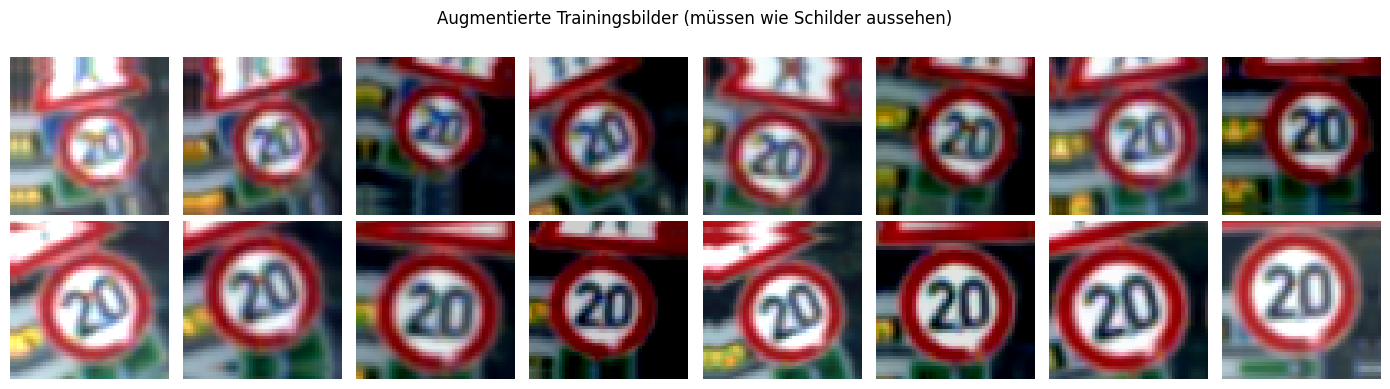

In [7]:
aug_batch = augment(X_tr[:16].astype("float32"), training=True).numpy()
assert aug_batch.max() > 1.5, "Augmentation läuft nicht auf 0-255!"
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, im in zip(ax.ravel(), aug_batch):
    a.imshow(np.clip(im, 0, 255).astype("uint8")); a.axis("off")
plt.suptitle("Augmentierte Trainingsbilder (müssen wie Schilder aussehen)")
plt.tight_layout(); plt.savefig(f"{args.out}/augmented.png", dpi=120); plt.show()

epochs = min(args.epochs, 10)
steps = epochs * math.ceil(len(X_tr) / args.batch)
try:   # Warmup + Cosine (Keras >= 3 / TF >= 2.13)
    lr = keras.optimizers.schedules.CosineDecay(
        0.0, steps, alpha=0.01, warmup_target=args.lr, warmup_steps=int(args.warmup_frac * steps))
except TypeError:
    lr = keras.optimizers.schedules.CosineDecay(args.lr, steps, alpha=0.01)
model.compile(
    optimizer=keras.optimizers.Adam(lr),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=args.label_smoothing),
    metrics=["accuracy"],
)

## 7. Training (max. 10 Epochen)

Epoch 1/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 47s 62ms/step - accuracy: 0.4750 - loss: 1.5104 - val_accuracy: 0.5159 - val_loss: 1.8331
Epoch 2/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 30s 58ms/step - accuracy: 0.8743 - loss: 0.6218 - val_accuracy: 0.9135 - val_loss: 0.9368
Epoch 3/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 30s 58ms/step - accuracy: 0.9591 - loss: 0.4346 - val_accuracy: 0.9797 - val_loss: 0.5582
Epoch 4/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 30s 58ms/step - accuracy: 0.9789 - loss: 0.3787 - val_accuracy: 0.9707 - val_loss: 0.5465
Epoch 5/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 30s 58ms/step - accuracy: 0.9838 - loss: 0.3585 - val_accuracy: 0.9956 - val_loss: 0.4675
Epoch 6/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 31s 59ms/step - accuracy: 0.9882 - loss: 0.3421 - val_accuracy: 0.9936 - val_loss: 0.4334
Epoch 7/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 30s 58ms/step - accuracy: 0.9889 - loss: 0.3323 - val_accuracy: 0.9875 - val_loss: 0.4835
Epoch 8/10
521/521 ━━━━━━━━━━━━━━━━━━━━ 31s 59ms/step - accuracy: 0.9931 - loss: 0.3190 - 

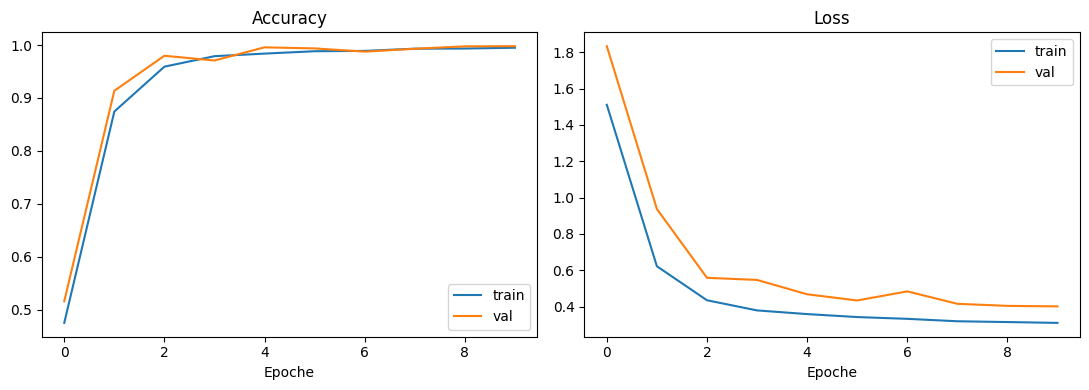

Differenz Train-Val Accuracy (Überanpassung): -0.0030


In [8]:
ckpt = keras.callbacks.ModelCheckpoint(f"{args.out}/best.weights.h5", monitor="val_loss",
                                       save_best_only=True, save_weights_only=True)
t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[ckpt])
train_time = time.time() - t0
model.load_weights(f"{args.out}/best.weights.h5")        # bestes Modell nach Val-Loss
model.save(f"{args.out}/gtsrb_resnet.keras")
json.dump({k: [float(v) for v in vs] for k, vs in hist.history.items()},
          open(f"{args.out}/training_log.json", "w"), indent=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, k, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    a.plot(hist.history[k], label="train"); a.plot(hist.history["val_" + k], label="val")
    a.set_title(t); a.set_xlabel("Epoche"); a.legend()
plt.tight_layout(); plt.savefig(f"{args.out}/training_curves.png", dpi=120); plt.show()
gap = hist.history["accuracy"][-1] - hist.history["val_accuracy"][-1]
print(f"Differenz Train-Val Accuracy (Überanpassung): {gap:+.4f}")

## 8. Test-Auswertung (Labels nur hier benutzt)

Val-Accuracy ohne TTA: 0.9978 | mit TTA: 0.9983 -> TTA AN
Test-Accuracy ohne TTA: 0.9918
TEST  Accuracy=0.9922  Macro-F1=0.9885  Loss=0.1016
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        60
           1     0.9958    0.9986    0.9972       720
           2     0.9987    0.9960    0.9973       750
           3     0.9932    0.9800    0.9866       450
           4     1.0000    0.9939    0.9970       660
           5     0.9843    0.9968    0.9905       630
           6     1.0000    0.9867    0.9933       150
           7     0.9978    0.9956    0.9967       450
           8     0.9956    1.0000    0.9978       450
           9     0.9979    1.0000    0.9990       480
          10     1.0000    0.9985    0.9992       660
          11     0.9976    0.9952    0.9964       420
          12     0.9985    0.9942    0.9964       690
          13     0.9972    0.9986    0.9979       720
          14     0.9818    1.0000    0.9908     

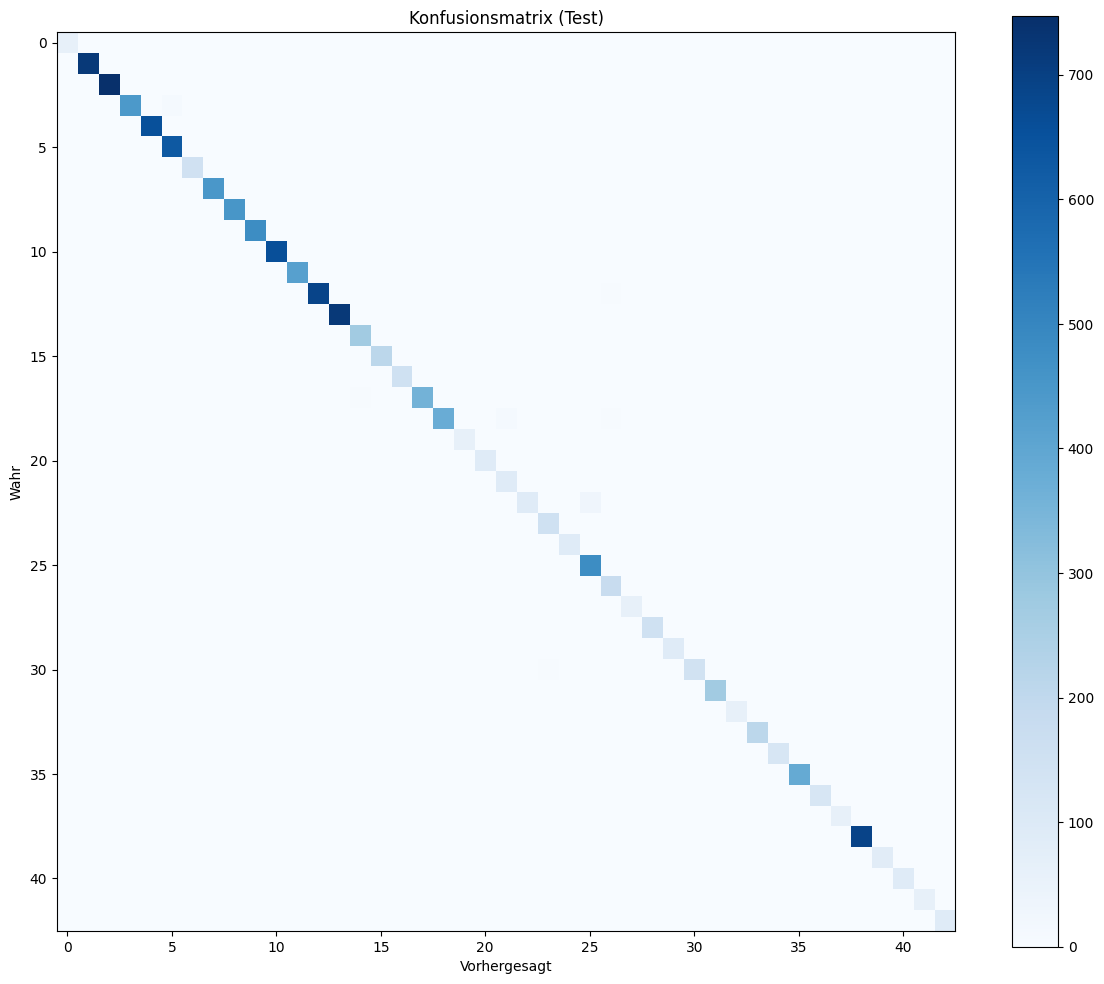

In [9]:
df = pd.read_csv(os.path.join(root, "Test.csv"))
X_te = np.array([load_img(os.path.join(root, pth)) for pth in df["Path"]])
y_te = df["ClassId"].values

def shift(Xa, dx, dy, pad=2):
    Xp = np.pad(Xa, ((0, 0), (pad, pad), (pad, pad), (0, 0)), mode="edge")
    return Xp[:, pad + dy: pad + dy + S, pad + dx: pad + dx + S]

def predict_tta(Xa):
    views = [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]
    return np.mean([model.predict(shift(Xa, dx, dy), batch_size=256, verbose=0) for dx, dy in views], axis=0)

# Entscheidung ob TTA genutzt wird: anhand der VALIDIERUNG (nicht anhand des Tests)
acc_val_plain = (model.predict(X_val, batch_size=256, verbose=0).argmax(1) == y_val).mean()
acc_val_tta = (predict_tta(X_val).argmax(1) == y_val).mean()
use_tta = acc_val_tta > acc_val_plain
print(f"Val-Accuracy ohne TTA: {acc_val_plain:.4f} | mit TTA: {acc_val_tta:.4f} -> TTA {'AN' if use_tta else 'AUS'}")

t0 = time.time()
proba_plain = model.predict(X_te, batch_size=256, verbose=0)
inf_ms = (time.time() - t0) / len(X_te) * 1000
proba = predict_tta(X_te) if use_tta else proba_plain
y_pred = proba.argmax(1)
print(f"Test-Accuracy ohne TTA: {accuracy_score(y_te, proba_plain.argmax(1)):.4f}")

acc = accuracy_score(y_te, y_pred)
macro_f1 = f1_score(y_te, y_pred, average="macro")
test_loss = float(-np.log(np.clip(proba[np.arange(len(y_te)), y_te], 1e-9, 1)).mean())
print(f"TEST  Accuracy={acc:.4f}  Macro-F1={macro_f1:.4f}  Loss={test_loss:.4f}")

report = classification_report(y_te, y_pred, digits=4)
print(report)
open(f"{args.out}/classification_report.txt", "w").write(report)

cm = confusion_matrix(y_te, y_pred, labels=range(NUM_CLASSES))
plt.figure(figsize=(12, 10)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.title("Konfusionsmatrix (Test)"); plt.xlabel("Vorhergesagt"); plt.ylabel("Wahr")
plt.tight_layout(); plt.savefig(f"{args.out}/confusion_matrix.png", dpi=120); plt.show()

## 9. Fehleranalyse

Top 10 Verwechslungen (wahr -> vorhergesagt : Anzahl):
  22 -> 25 : 30
  18 -> 21 : 9
   3 ->  5 : 9
  30 -> 23 : 5
  17 -> 14 : 4
  18 -> 26 : 3
  12 -> 26 : 3
  35 ->  3 : 2
  15 -> 13 : 2
   4 -> 20 : 2
5 schwächste Klassen (F1): [(22, 0.853), (21, 0.952), (39, 0.966), (30, 0.966), (25, 0.968)]
Mittlere Konfidenz richtig: 0.928 | falsch: 0.520


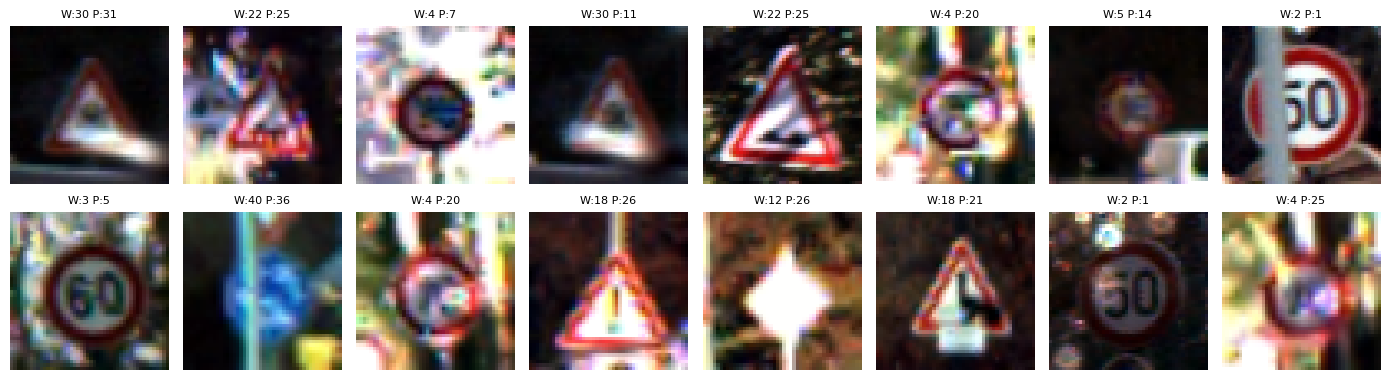

In [10]:
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
print("Top 10 Verwechslungen (wahr -> vorhergesagt : Anzahl):")
for r, c in np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:10], cm_off.shape))[0]:
    print(f"  {r:2d} -> {c:2d} : {cm_off[r, c]}")

f1s = f1_score(y_te, y_pred, average=None)
print("5 schwächste Klassen (F1):", [(int(i), round(float(f1s[i]), 3)) for i in np.argsort(f1s)[:5]])

conf = proba.max(1)
print(f"Mittlere Konfidenz richtig: {conf[y_pred == y_te].mean():.3f} | falsch: {conf[y_pred != y_te].mean():.3f}")

wrong = np.where(y_pred != y_te)[0][:16]
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, i in zip(ax.ravel(), wrong):
    a.imshow(X_te[i]); a.set_title(f"W:{y_te[i]} P:{y_pred[i]}", fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(f"{args.out}/errors.png", dpi=120); plt.show()

## 10. Effizienz + Zusammenfassung

In [11]:
summary = dict(parameters=int(model.count_params()), train_time_s=round(train_time, 1),
               inference_ms_per_image=round(inf_ms, 3), test_accuracy=float(acc),
               macro_f1=float(macro_f1), used_tta=bool(use_tta), test_loss=test_loss, train_val_acc_gap=float(gap))
json.dump(summary, open(f"{args.out}/summary.json", "w"), indent=2)
print(summary)

{'parameters': 1262631, 'train_time_s': 320.6, 'inference_ms_per_image': 0.211, 'test_accuracy': 0.9921615201900238, 'macro_f1': 0.9884636007208535, 'used_tta': True, 'test_loss': 0.10158364474773407, 'train_val_acc_gap': -0.002965688705444336}


## Kurze Modellbeschreibung (für die Abgabe)

- **Daten:** 43 Klassen, RGB, Autocontrast, Resize 48×48, Normalisierung 1/255. Validierungs-Split nach Tracks (kein Leakage).
- **Modell:** Conv-Stem + 4 Residual-Blöcke (32→64→128→256) mit Squeeze-Excitation, GlobalAveragePooling, Dropout 0.3, Softmax(43), ca. 1,26 Mio. Parameter.
- **Training:** Adam, Cross-Entropy (Label Smoothing 0.05), Warmup + Cosine-LR, 10 Epochen, Augmentation (Rotation, Zoom, Translation, Kontrast, Helligkeit; kein Flip).
- **Ungleichgewicht:** abgeschwächte Klassengewichte (Wurzel von „balanced“).
- **Ergebnisse:** Test-Accuracy = …, Macro-F1 = …, Inferenz = … ms/Bild *(aus `summary.json` eintragen)*.
- **Analyse:** Überanpassung (Train-Val-Differenz), häufigste Verwechslungen, schwächste Klassen, Konfidenz bei Fehlern.